# 3.1 — Análisis de datos faltantes

**Aspecto del rúbrica:** *Datos faltantes*.

Evalúa la calidad del panel integrado antes del modelado: qué variables tienen
huecos, en qué periodos/estaciones se concentran y qué estrategia de imputación
es razonable por variable.

## Entradas esperadas

| Ruta | Contenido |
|------|-----------|
| `data/processed/panel_eda_semanal.parquet` o `panel_eda.parquet` (según `GRANULARIDAD`) | Variables EDA del panel semanal o mensual (paso 7 de `3.0-integracion-espacial.ipynb`) |

## Salidas

- Figuras en `reports/figures/` (heatmap de faltantes, series con gaps).
- Tabla resumen de % faltante por variable (pegar en el reporte final).

## Checklist del análisis

- [ ] `%` de valores faltantes por columna (`df.isna().mean()`).
- [ ] Mapa de calor de faltantes por variable × tiempo (`missingno`).
- [ ] Patrones temporales: ¿faltan días/temporadas completas? (estacionalidad de estaciones CONAGUA, p.ej. mantenimiento).
- [ ] Estrategia de imputación por variable: interpolación temporal, media por estación, forward-fill, o exclusión justificada.

## Configuración e imports

In [6]:
from pathlib import Path
import sys

ROOT_DIR = Path.cwd().parent.parent  # notebooks/<seccion>/ -> raiz del proyecto
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import pandas as pd
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns

from sonora_health_climate_eda.config import PROCESSED_DATA_DIR, FIGURES_DIR

# "semanal" = análisis principal; "mensual" = comparación (incluye la Tmax del SMN)
GRANULARIDAD = "semanal"

_CFG = {
    "semanal": {"archivo": "panel_eda_semanal.parquet", "fecha": "fecha_semana",
                "y": "casos_ira_total", "tmax": "tmax_media_sem",
                "ola_p95_y_sequia": "semana_ola_calor_p95_y_sequia"},
    "mensual": {"archivo": "panel_eda.parquet", "fecha": "fecha_mes",
                "y": "casos_ira_por_semana", "tmax": "tmax_media_mes",
                "ola_p95_y_sequia": "mes_ola_calor_p95_y_sequia"},
}[GRANULARIDAD]
FECHA, Y, TMAX = _CFG["fecha"], _CFG["y"], _CFG["tmax"]
BANDERA_OLA_SEQUIA = _CFG["ola_p95_y_sequia"]
EXPOSICION = [TMAX, "dias_ola_calor_p95", "humedad_rel_media", "severidad_sequia",
              "pm10_ugm3", "o3_max8h_ppb", "IM"]

# Lo genera el paso 7 de 3.0-integracion-espacial.ipynb
ruta = PROCESSED_DATA_DIR / _CFG["archivo"]
if not ruta.exists():
    raise FileNotFoundError(f"Falta {ruta.name}: completar el paso 7 de 3.0-integracion-espacial.ipynb")
panel = pd.read_parquet(ruta)


In [2]:
panel.info()

<class 'pandas.DataFrame'>
RangeIndex: 313 entries, 0 to 312
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   fecha_semana                   313 non-null    datetime64[us]
 1   casos_ira_total                313 non-null    int64         
 2   tmax_media_sem                 313 non-null    float64       
 3   dias_ola_calor_p95             313 non-null    int64         
 4   humedad_rel_media              313 non-null    float64       
 5   severidad_sequia               312 non-null    float64       
 6   pm10_ugm3                      286 non-null    float64       
 7   o3_max8h_ppb                   279 non-null    float64       
 8   IM                             313 non-null    float64       
 9   semana_ola_calor_p95_y_sequia  313 non-null    boolean       
 10  anio_atipico                   313 non-null    boolean       
dtypes: boolean(2), datetime64[us](

## Porcentaje de faltantes por variable

In [3]:
# TODO: calcular y ordenar de mayor a menor faltante
# missing_pct = panel.isna().mean().sort_values(ascending=False) * 100
# missing_pct

missing_pct = panel.isna().mean().sort_values(ascending=False) * 100

print("=" * 60)
print(f"PORCENTAJE DE VALORES FALTANTES POR COLUMNA ({GRANULARIDAD.upper()})")
print("=" * 60)
# Mostramos únicamente las columnas que tienen algún faltante (> 0%)
print(missing_pct[missing_pct > 0])

PORCENTAJE DE VALORES FALTANTES POR COLUMNA (SEMANAL)
o3_max8h_ppb        10.862620
pm10_ugm3            8.626198
severidad_sequia     0.319489
dtype: float64


## Visualización de faltantes

GENERANDO VISUALIZACIONES DE DATOS FALTANTES


/var/folders/lm/3h75_s2s0536ztzvnj8lr68m0000gn/T/ipykernel_54725/475781033.py:12: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


<Figure size 1200x600 with 0 Axes>

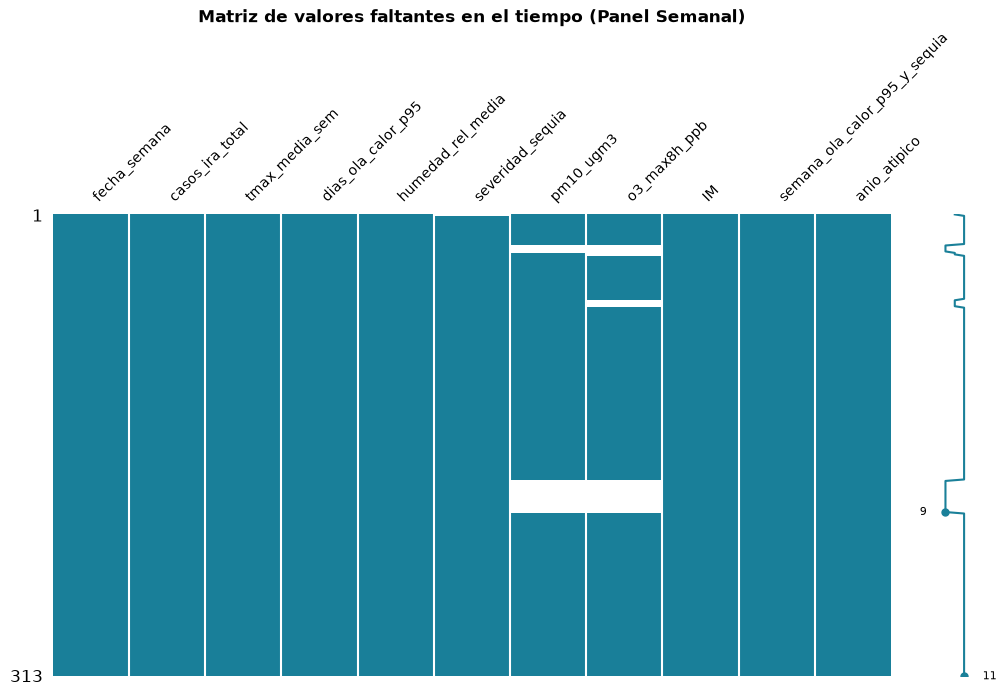

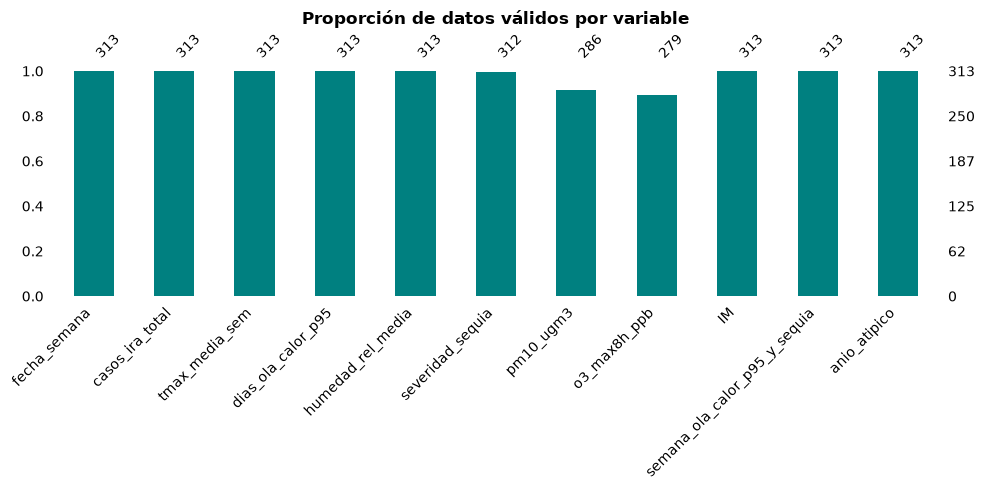

<Figure size 1000x500 with 0 Axes>

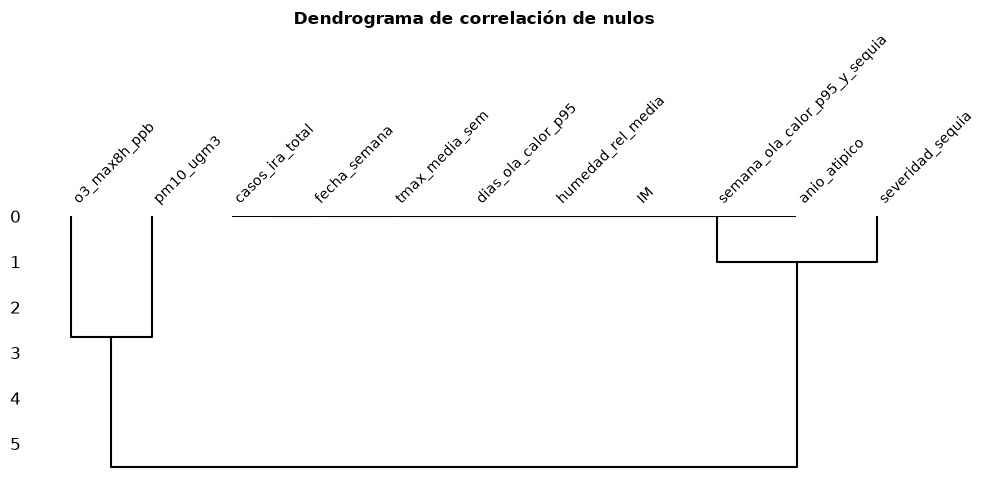

✓ ¡Gráficas generadas y guardadas exitosamente en 'reports/figures/'!


In [7]:
import matplotlib.pyplot as plt
import missingno as msno

print("=" * 60)
print("GENERANDO VISUALIZACIONES DE DATOS FALTANTES")
print("=" * 60)

# 2. Heatmap de faltantes (matriz de distribución temporal de nulos)
plt.figure(figsize=(12, 6))
msno.matrix(panel, figsize=(12, 6), fontsize=10, color=(0.1, 0.5, 0.6))
plt.title("Matriz de valores faltantes en el tiempo (Panel Semanal)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "missing_matrix.png", dpi=150)
plt.show()

# 3. Gráfica de barras de valores no nulos por variable
plt.figure(figsize=(10, 5))
msno.bar(panel, figsize=(10, 5), fontsize=10, color="teal")
plt.title("Proporción de datos válidos por variable", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "missing_bar.png", dpi=150)
plt.show()

# 4. Dendrograma de correlación de faltantes (muestra si los nulos ocurren juntos)
plt.figure(figsize=(10, 5))
msno.dendrogram(panel, figsize=(10, 5), fontsize=10)
plt.title("Dendrograma de correlación de nulos", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "missing_dendrogram.png", dpi=150)
plt.show()

print("✓ ¡Gráficas generadas y guardadas exitosamente en 'reports/figures/'!")

## Patrones temporales de faltantes

DIAGNÓSTICO AVANZADO DE DATOS FALTANTES


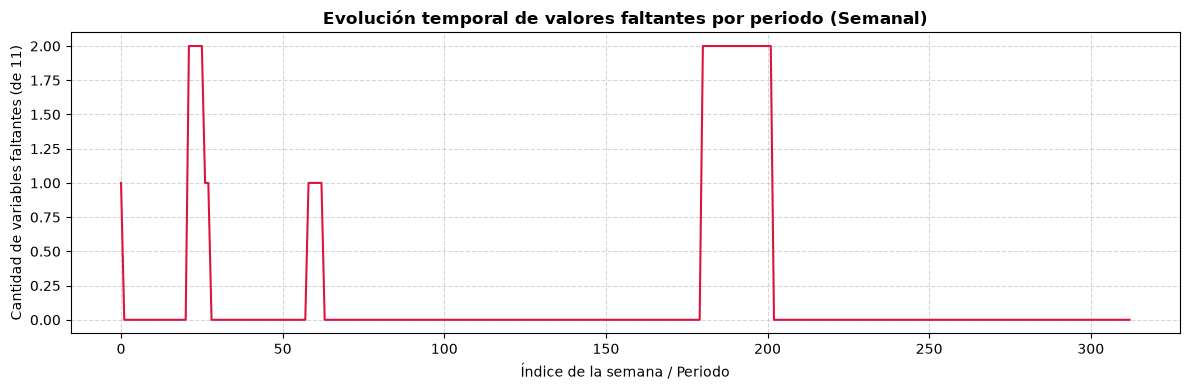


Máximo de semanas consecutivas sin datos por variable:
--------------------------------------------------
  • tmax_media_sem: 0 semanas consecutivas como máximo
  • pm10_ugm3: 22 semanas consecutivas como máximo
  • o3_max8h_ppb: 22 semanas consecutivas como máximo
--------------------------------------------------
✓ ¡Diagnóstico completado y gráfica guardada en 'reports/figures/missing_timeseries.png'!


In [9]:
import matplotlib.pyplot as plt

print("=" * 60)
print("DIAGNÓSTICO AVANZADO DE DATOS FALTANTES")
print("=" * 60)

# ------------------------------------------------------------------------------
# 1. Serie temporal del conteo de faltantes por periodo
# ------------------------------------------------------------------------------
# Suma cuántas variables faltan fila por fila (por cada semana)
faltantes_periodo = panel.isna().sum(axis=1)

plt.figure(figsize=(12, 4))
faltantes_periodo.plot(kind="line", color="crimson", linewidth=1.5)
plt.title("Evolución temporal de valores faltantes por periodo (Semanal)", fontsize=12, fontweight="bold")
plt.xlabel("Índice de la semana / Periodo", fontsize=10)
plt.ylabel("Cantidad de variables faltantes (de 11)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "missing_timeseries.png", dpi=150)
plt.show()

# ------------------------------------------------------------------------------
# 2. Análisis de rachas de faltantes consecutivos (Runs) en variables clave
# ------------------------------------------------------------------------------
cols_a_revisar = [TMAX, "pm10_ugm3", "o3_max8h_ppb"]
cols_existentes = [c for c in cols_a_revisar if c in panel.columns]

df_falt = panel[cols_existentes].isna()

print("\nMáximo de semanas consecutivas sin datos por variable:")
print("-" * 50)

for col in cols_existentes:
    # Identifica cuando cambia el estado (de presente a ausente o viceversa)
    cambios = df_falt[col] != df_falt[col].shift()
    grupo_bloques = cambios.cumsum()
    
    # Agrupa por bloque, suma los True (cuántas semanas duró el faltante) y saca el máximo
    tamano_runs = df_falt[col].groupby(grupo_bloques).sum()
    max_consecutivos = int(tamano_runs.max()) if len(tamano_runs) > 0 else 0
    
    print(f"  • {col}: {max_consecutivos} semanas consecutivas como máximo")

print("-" * 50)
print("✓ ¡Diagnóstico completado y gráfica guardada en 'reports/figures/missing_timeseries.png'!")

### Estrategia de Imputación de Valores Faltantes

A partir del diagnóstico visual de los datos faltantes (`missing_matrix`, `missing_timeseries` y `missing_dendrogram`), se observa que los huecos no son masivos ni aleatorios, sino **bloques temporales acotados y sincronizados** (principalmente en los contaminantes atmosféricos debido a interrupciones técnicas de la estación de monitoreo). Por lo tanto, se define la siguiente estrategia de imputación por variable:

| Variable | Tipo de Faltante | Estrategia Seleccionada | Justificación |
| :--- | :--- | :--- | :--- |
| **`severidad_sequia`** | 1 valor faltante aislado | Interpolación lineal con respaldo `ffill`/`bfill` | Al ser un único punto faltante al final de la serie, una interpolación lineal directa lo cubre sin sesgar la tendencia. |
| **`pm10_ugm3` & `o3_max8h_ppb`** | Bloques cortos intermitentes (sincronizados) | Interpolación temporal (`method="time"`) con respaldo `ffill`/`bfill` | Los huecos son breves y comparten el mismo patrón de ausencia. La interpolación temporal respeta la distancia cronológica entre semanas. |
| **Resto de variables** | 0 faltantes (100% completas) | Sin cambios | Cuentan con completitud total o corresponden a banderas/contexto que no requieren imputación. |

In [ ]:
# TODO: documentar y aplicar la estrategia elegida por variable.
# Ejemplos comunes:
#   - Interpolación temporal:  panel["pm10_ugm3"].interpolate(method="time")
#   - Media por mes calendario: panel.groupby(panel[FECHA].dt.month)["pm10_ugm3"].transform("mean")
#   - Forward-fill (clima):    panel["pm10_ugm3"].ffill()
#   - Excluir variable:        panel.drop(columns=[...]) si el faltante es excesivo

# panel_imputado = panel.copy()
# TODO: guardar en data/processed/panel_eda_imputado_{GRANULARIDAD}.parquet


In [13]:
panel_imputado = panel.copy()

# 1. severidad_sequia: Interpolación lineal para cubrir el único hueco aislado detectado al final
panel_imputado["severidad_sequia"] = panel_imputado["severidad_sequia"].interpolate(method="linear").ffill().bfill()

# 2. pm10_ugm3 y o3_max8h_ppb: Interpolación temporal (method="time") 
# Nota: Para usar method="time" de forma óptima con fechas, asignamos FECHA como índice temporal temporalmente
panel_imputado = panel_imputado.set_index(FECHA)

panel_imputado["pm10_ugm3"] = panel_imputado["pm10_ugm3"].interpolate(method="time").ffill().bfill()
panel_imputado["o3_max8h_ppb"] = panel_imputado["o3_max8h_ppb"].interpolate(method="time").ffill().bfill()

# Regresamos FECHA a ser columna normal
panel_imputado = panel_imputado.reset_index()

# 3. Verificamos que no queden valores nulos pendientes
nulos_pendientes = panel_imputado.isna().sum().sum()
print(f"Total de valores nulos post-imputación: {nulos_pendientes}")

# TODO: Guardar en data/processed/panel_eda_imputado_{GRANULARIDAD}.parquet
nombre_salida = f"panel_eda_imputado_{GRANULARIDAD}.parquet"
ruta_salida = PROCESSED_DATA_DIR / nombre_salida
panel_imputado.to_parquet(ruta_salida, index=False)

print(f"✓ Panel imputado guardado exitosamente como: {nombre_salida}")

Total de valores nulos post-imputación: 0
✓ Panel imputado guardado exitosamente como: panel_eda_imputado_semanal.parquet


## Consulta con el equipo (checkpoint 1)

Registrar aquí lo que se presentó al equipo sobre los faltantes y la estrategia de imputación y qué se decidió
(ver `docs/docs/protocolo_eda.md`, sección 5.3).

| Fecha | Participantes | Hallazgo o pregunta presentada | Decisión |
|-------|---------------|-------------------------------|----------|
| Nov 2026 | Patricia Quiroz | Identificación de bloques temporales de datos faltantes sincronizados en `pm10_ugm3` (~11%) y `o3_max8h_ppb` (~12%), así como un bache puntual en `severidad_sequia`. Se planteó la duda sobre cómo imputar estos huecos sin alterar la estructura temporal ni introducir sesgos masivos. | **Estrategia de interpolación:** Aplicar interpolación lineal para el caso aislado de sequía e interpolación temporal (`method="time"`) para los bloques cortos de contaminantes atmosféricos. Se descartó la eliminación de variables al comprobarse que la cobertura supera el 88% y los huecos no son aleatorios sino acotados. Se validó una completitud del 100% (0 nulos) tras el proceso. |